Dataset Medical Cost Personal Datasets pada file insurance.csv berisi 1.338 observasi dan 7 variabel, tanpa nilai kosong. Fitur yang digunakan adalah age (usia), sex (jenis kelamin), bmi (indeks massa tubuh), children (jumlah anak/tanggungan), smoker (status merokok), dan region (wilayah tempat tinggal). Target charges adalah biaya medis personal yang ditagihkan oleh asuransi.

Model multiple linear regression menggunakan keenam fitur tersebut. Data dibagi menjadi 80% data latih dan 20% data uji. Fitur kategori dikodekan dengan one-hot encoding dan fitur numerik distandardisasi. Kedua transformasi hanya dilatih menggunakan data latih.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
dataset_path = Path('insurance.csv')
if not dataset_path.is_file():
    dataset_path = Path('Pertemuan_7') / 'insurance.csv'

data = pd.read_csv(dataset_path)
print('Ukuran dataset:', data.shape)
print('Jumlah nilai kosong:')
print(data.isna().sum())
data.head()

Ukuran dataset: (1338, 7)
Jumlah nilai kosong:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
data.describe(include='all')

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


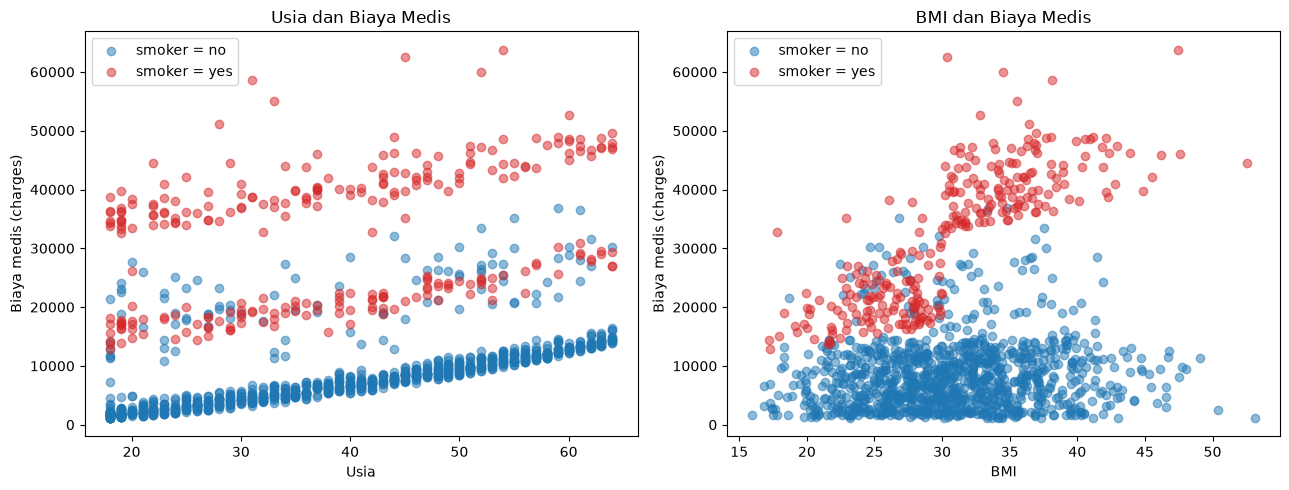

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for status, warna in [('no', 'tab:blue'), ('yes', 'tab:red')]:
    subset = data[data['smoker'] == status]
    axes[0].scatter(subset['age'], subset['charges'], color=warna,
                    alpha=0.5, label=f'smoker = {status}')
    axes[1].scatter(subset['bmi'], subset['charges'], color=warna,
                    alpha=0.5, label=f'smoker = {status}')

axes[0].set_xlabel('Usia')
axes[0].set_ylabel('Biaya medis (charges)')
axes[0].set_title('Usia dan Biaya Medis')
axes[1].set_xlabel('BMI')
axes[1].set_ylabel('Biaya medis (charges)')
axes[1].set_title('BMI dan Biaya Medis')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [5]:
fitur_numerik = ['age', 'bmi', 'children']
fitur_kategori = ['sex', 'smoker', 'region']

X = data[fitur_numerik + fitur_kategori]
y = data['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data latih: 1070
Jumlah data uji: 268


In [6]:
preprocessor = ColumnTransformer([
    ('numerik', StandardScaler(), fitur_numerik),
    ('kategori', OneHotEncoder(drop='first', handle_unknown='ignore'), fitur_kategori)
])

model = Pipeline([
    ('preprocessing', preprocessor),
    ('regresi', LinearRegression())
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regresi', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','bmi','children','sex','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerik', ...), ('kategori', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenat

In [7]:
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

hasil_prediksi = pd.DataFrame({
    'Biaya aktual': y_test,
    'Biaya prediksi': y_pred,
    'Residual': y_test - y_pred
})
hasil_prediksi.head(10)

,Biaya aktual,Biaya prediksi,Residual
764,9095.06825,8969.550274,125.517976
887,5272.17580,7068.747443,-1796.571643
890,29330.98315,36858.410912,-7527.427762
1293,9301.89355,9454.678501,-152.784951
259,33750.29180,26973.173457,6777.118343
1312,4536.25900,10864.113164,-6327.854164
899,2117.33885,170.280841,1947.058009
752,14210.53595,16903.450287,-2692.914337
1286,3732.62510,1092.430936,2640.194164
707,10264.44210,11218.343184,-953.901084


In [8]:
r2_train = r2_score(y_train, y_train_pred)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'R-squared data latih: {r2_train:.6f}')
print(f'R-squared data uji: {r2:.6f}')
print(f'MSE data uji: {mse:.2f}')
print(f'MAE data uji: {mae:.2f}')

R-squared data latih: 0.741726
R-squared data uji: 0.783593
MSE data uji: 33596915.85
MAE data uji: 4181.19


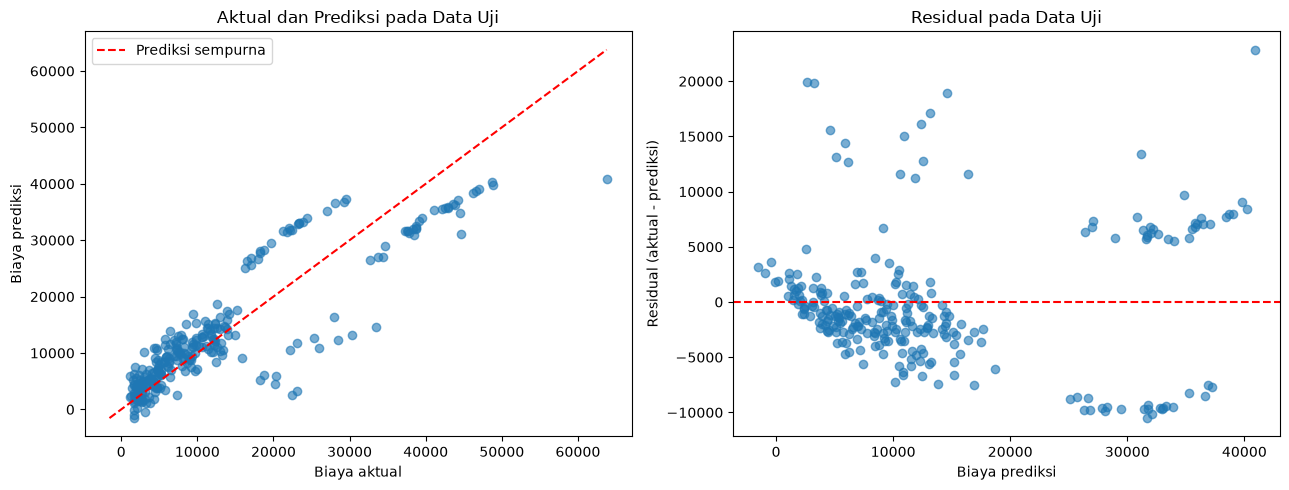

In [9]:
residual = y_test - y_pred
batas = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.6)
axes[0].plot(batas, batas, color='red', linestyle='--', label='Prediksi sempurna')
axes[0].set_xlabel('Biaya aktual')
axes[0].set_ylabel('Biaya prediksi')
axes[0].set_title('Aktual dan Prediksi pada Data Uji')
axes[0].legend()

axes[1].scatter(y_pred, residual, alpha=0.6)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Biaya prediksi')
axes[1].set_ylabel('Residual (aktual - prediksi)')
axes[1].set_title('Residual pada Data Uji')
plt.tight_layout()
plt.show()

Model menghasilkan R-squared data latih sebesar **0,7417** dan data uji sebesar **0,7836**. Pada pembagian data ini, model menjelaskan sekitar **78,36%** variasi biaya medis pada data uji. Kedua nilai relatif berdekatan, sehingga tidak terlihat penurunan kinerja pada data uji dibandingkan data latih.

MAE data uji sebesar **4.181,19** berarti rata-rata selisih absolut prediksi terhadap biaya aktual adalah sebesar nilai tersebut dalam satuan biaya pada dataset. MSE sebesar **33.596.915,85** memiliki satuan biaya kuadrat dan memberi penalti lebih besar pada kesalahan prediksi yang besar. Grafik aktual-prediksi dan residual menunjukkan bahwa masih ada prediksi yang meleset jauh. Pada seperempat data uji dengan biaya aktual tertinggi, rata-rata residual positif sebesar **3.619,44**, yang menunjukkan kecenderungan model memprediksi terlalu rendah pada kelompok tersebut. Terdapat **4 prediksi negatif**, yang tidak sesuai dengan makna biaya medis. Regresi linier tidak membatasi keluaran menjadi positif.

Hasil ini menunjukkan bahwa model menangkap sebagian besar variasi target, tetapi masih memiliki keterbatasan dalam menggambarkan pola biaya medis. Evaluasi ini menggunakan satu pembagian data latih-uji.